# The players and the style

1. **Chelsea's players against the league's top 10** (Understat, 2016/17).
2. **Who did the finishing?** Goals vs expected goals for every Chelsea player.
3. **Who improved?** Returning players, per 90 minutes, 2015/16 vs 2016/17.
4. **The signings**, and Kanté at Leicester vs Chelsea (official Opta stats).
5. **The team's style** from official Premier League (Opta) club stats: Chelsea against the league, and against their own 10th-place season.

Every chart shows the league's top 10 or all 20 clubs, so a "best in the league" claim can be checked against the competition.

In [1]:
from pathlib import Path
import html
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
sys.path.insert(0, str(REPO / "src"))
from football_analytics.viz import leaderboard

U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
CHE = "Chelsea"
BLUE, GREY, DARK, MUTED, GOLD = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#FDBE11"
GOLD_TEXT = "#9A7200"  # darker gold for text on white
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def titles(fig, title, subtitle, source):
    """Title above the axes (va=bottom) and subtitle just under it (va=top) so they never overlap."""
    fig.suptitle(title, x=0.01, y=1.06, ha="left", va="bottom", fontsize=14, fontweight="bold", color=DARK)
    fig.text(0.01, 1.055, subtitle, ha="left", va="top", fontsize=10, color=MUTED)
    fig.text(0.01, -0.04, source, ha="left", va="top", fontsize=8, color=MUTED)


def load_shots(season):
    d = pd.read_csv(U / f"shots_epl_{season}.csv")
    d["team"] = np.where(d.h_a == "h", d.h_team, d.a_team)
    d["opp"] = np.where(d.h_a == "h", d.a_team, d.h_team)
    d["goal"] = d.result == "Goal"
    d["date"] = pd.to_datetime(d.date)
    d["player"] = d.player.map(html.unescape)
    return d


def load_players(season):
    p = pd.read_csv(U / f"players_epl_{season}.csv")
    p["player_name"] = p.player_name.map(html.unescape)
    p["team"] = p.team_title.str.split(",").str[-1]  # players who moved mid-season: last club
    return p


def matches(shots):
    """One row per team per match: goals, xG for and against, points."""
    g = shots.groupby("match_id").agg(date=("date", "first"), h=("h_team", "first"), a=("a_team", "first"),
                                      hg=("h_goals", "first"), ag=("a_goals", "first"))
    xg = shots.groupby(["match_id", "team"]).xG.sum()
    rows = []
    for mid, r in g.iterrows():
        for team, opp, gf, ga in [(r.h, r.a, r.hg, r.ag), (r.a, r.h, r.ag, r.hg)]:
            rows.append(dict(match_id=mid, date=r.date, team=team, opp=opp, home=team == r.h, gf=gf, ga=ga,
                             xgf=xg.get((mid, team), 0.0), xga=xg.get((mid, opp), 0.0),
                             pts=3 if gf > ga else 1 if gf == ga else 0))
    m = pd.DataFrame(rows).sort_values(["team", "date"])
    m["n"] = m.groupby("team").cumcount() + 1
    return m


def expected_points(shots, sims=10_000, seed=42):
    """Replay every match `sims` times: each shot is a goal with probability = its xG."""
    rng = np.random.default_rng(seed)
    out = {}
    for mid, g in shots.groupby("match_id"):
        h, a = g.h_team.iloc[0], g.a_team.iloc[0]
        hx, ax = g[g.team == h].xG.values, g[g.team == a].xG.values
        sh = (rng.random((sims, len(hx))) < hx).sum(1)
        sa = (rng.random((sims, len(ax))) < ax).sum(1)
        out[(mid, h)] = (3 * (sh > sa) + (sh == sa)).mean()
        out[(mid, a)] = (3 * (sa > sh) + (sa == sh)).mean()
    return pd.Series(out, name="xpts")

In [2]:
P = {"2015/16": load_players("15-16"), "2016/17": load_players("16-17")}
p = P["2016/17"].copy()
p["np_goals"] = p.npg
print(len(p), "players in 2016/17;", (p.team == CHE).sum(), "played for Chelsea")

524 players in 2016/17; 23 played for Chelsea


## 1. Chelsea's players against the league's top 10

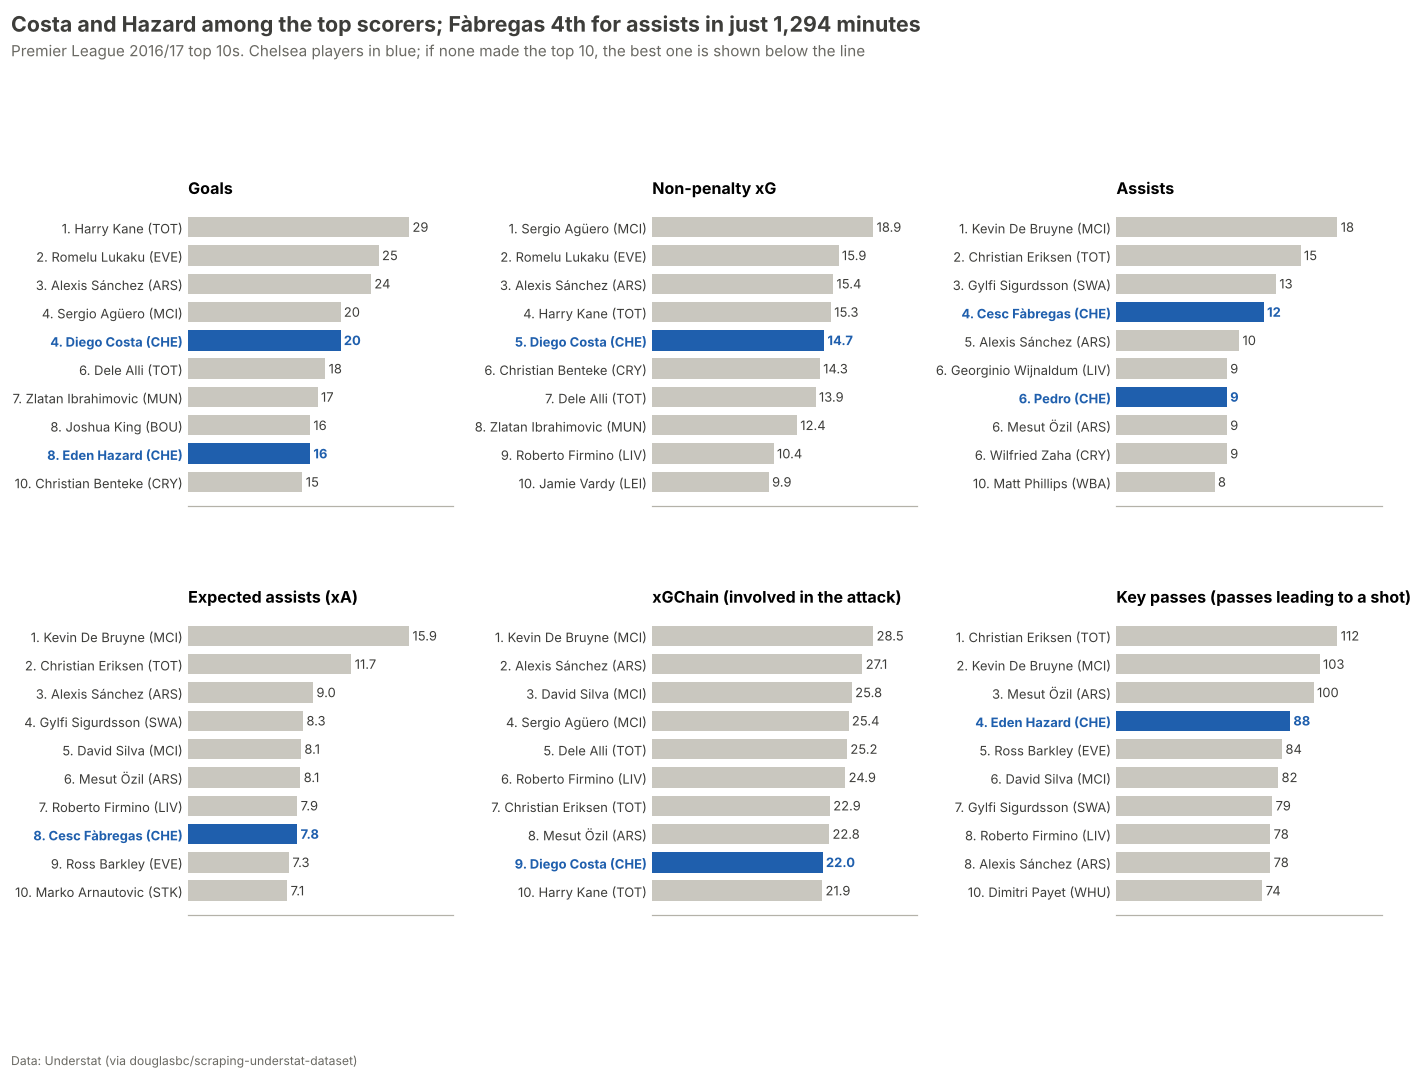

In [3]:
panels = [("goals", "Goals", "{:.0f}"), ("npxG", "Non-penalty xG", "{:.1f}"), ("assists", "Assists", "{:.0f}"),
          ("xA", "Expected assists (xA)", "{:.1f}"), ("xGChain", "xGChain (involved in the attack)", "{:.1f}"),
          ("key_passes", "Key passes (passes leading to a shot)", "{:.0f}")]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))
for ax, (col, lab, fmt) in zip(axes.flat, panels):
    leaderboard(ax, p[col], p.player_name, p.team, highlight_team=CHE, fmt=fmt, title=lab)
fig.subplots_adjust(wspace=0.75, hspace=0.35)
titles(fig, "Costa and Hazard among the top scorers; Fàbregas 4th for assists in just 1,294 minutes",
       "Premier League 2016/17 top 10s. Chelsea players in blue; if none made the top 10, the best one is shown below the line",
       SRC_U)
fig.savefig(FIGS / "09_leaderboards_attack.png")

## 2. Who did the finishing?

,player_name,time,npg,npxG,diff
4,Diego Costa,3101,20,14.7,5.3
8,Eden Hazard,3050,14,8.7,5.3
30,Willian,1509,8,3.8,4.2
22,Pedro,2178,9,6.0,3.0
48,Gary Cahill,3299,6,3.3,2.7
66,Cesc Fàbregas,1294,5,2.8,2.2
57,Marcos Alonso,2696,6,4.1,1.9
71,Michy Batshuayi,221,5,3.8,1.2
103,Nathan Aké,826,3,2.2,0.8
232,John Terry,489,1,1.5,-0.5


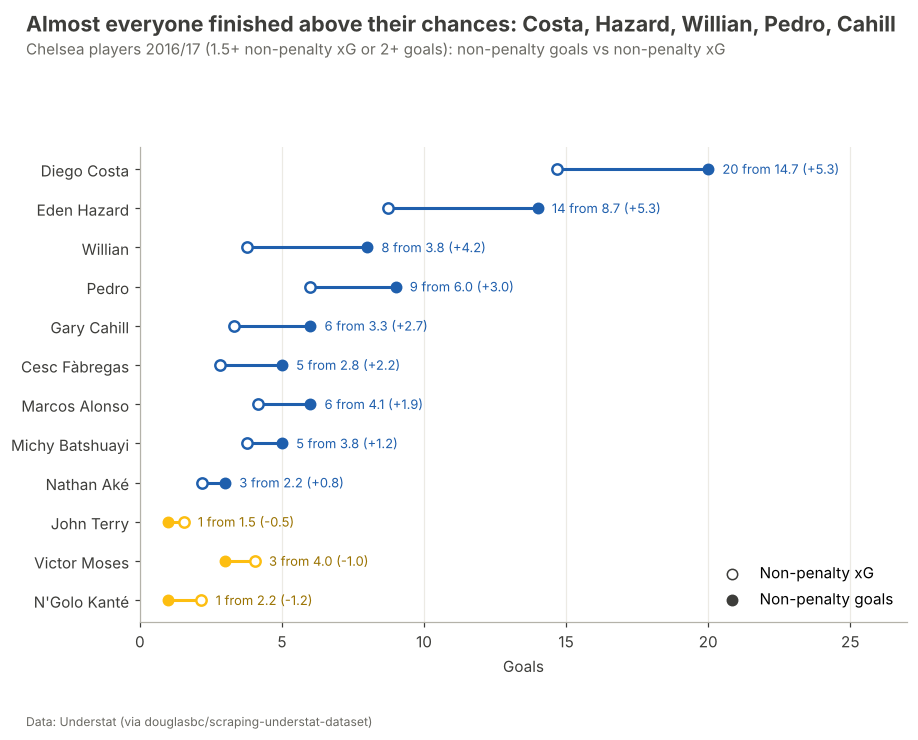

In [4]:
c = p[(p.team == CHE) & ((p.npxG >= 1.5) | (p.npg >= 2))].copy()
c["diff"] = c.npg - c.npxG
c = c.sort_values("diff")
fig, ax = plt.subplots(figsize=(9, 5.6))
y = np.arange(len(c))
for yi, r in zip(y, c.itertuples()):
    col = BLUE if r.diff > 0 else GOLD
    ax.plot([r.npxG, r.npg], [yi, yi], color=col, lw=2)
    ax.scatter(r.npxG, yi, s=46, facecolor="white", edgecolor=col, lw=1.6, zorder=2)
    ax.scatter(r.npg, yi, s=46, color=col, zorder=3)
    ax.text(max(r.npg, r.npxG) + 0.5, yi, f"{r.npg:.0f} from {r.npxG:.1f} ({r.diff:+.1f})", va="center", fontsize=8.5,
            color=BLUE if r.diff > 0 else GOLD_TEXT)
ax.set_yticks(y, c.player_name)
ax.scatter([], [], s=46, facecolor="white", edgecolor=DARK, label="Non-penalty xG")
ax.scatter([], [], s=46, color=DARK, label="Non-penalty goals")
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(0, 27); ax.set_xlabel("Goals"); ax.grid(axis="y", visible=False)
tot = c["diff"].sum()
titles(fig, "Almost everyone finished above their chances: Costa, Hazard, Willian, Pedro, Cahill",
       "Chelsea players 2016/17 (1.5+ non-penalty xG or 2+ goals): non-penalty goals vs non-penalty xG", SRC_U)
fig.savefig(FIGS / "10_finishing_by_player.png")
c[["player_name", "time", "npg", "npxG", "diff"]].round(1).sort_values("diff", ascending=False)

## 3. Who improved? Returning players, per 90 minutes

Players with 900+ minutes for Chelsea in both seasons.

,npg,npxG,assists,xA,key_passes,xGChain,xGBuildup
player_name,,,,,,,
César Azpilicueta,-53.0,-50.0,25.0,-30.0,-2.0,-5.0,-6.0
Gary Cahill,78.0,30.0,-100.0,-49.0,-1.0,143.0,161.0
Diego Costa,28.0,-7.0,-10.0,31.0,8.0,-6.0,-5.0
Eden Hazard,151.0,143.0,19.0,10.0,-5.0,24.0,-22.0
Nemanja Matic,-55.0,-59.0,215.0,33.0,23.0,-13.0,-9.0
Pedro,22.0,-7.0,326.0,13.0,-5.0,-4.0,-8.0
Willian,193.0,56.0,-39.0,-27.0,15.0,27.0,27.0
Cesc Fàbregas,274.0,168.0,284.0,109.0,107.0,32.0,-4.0


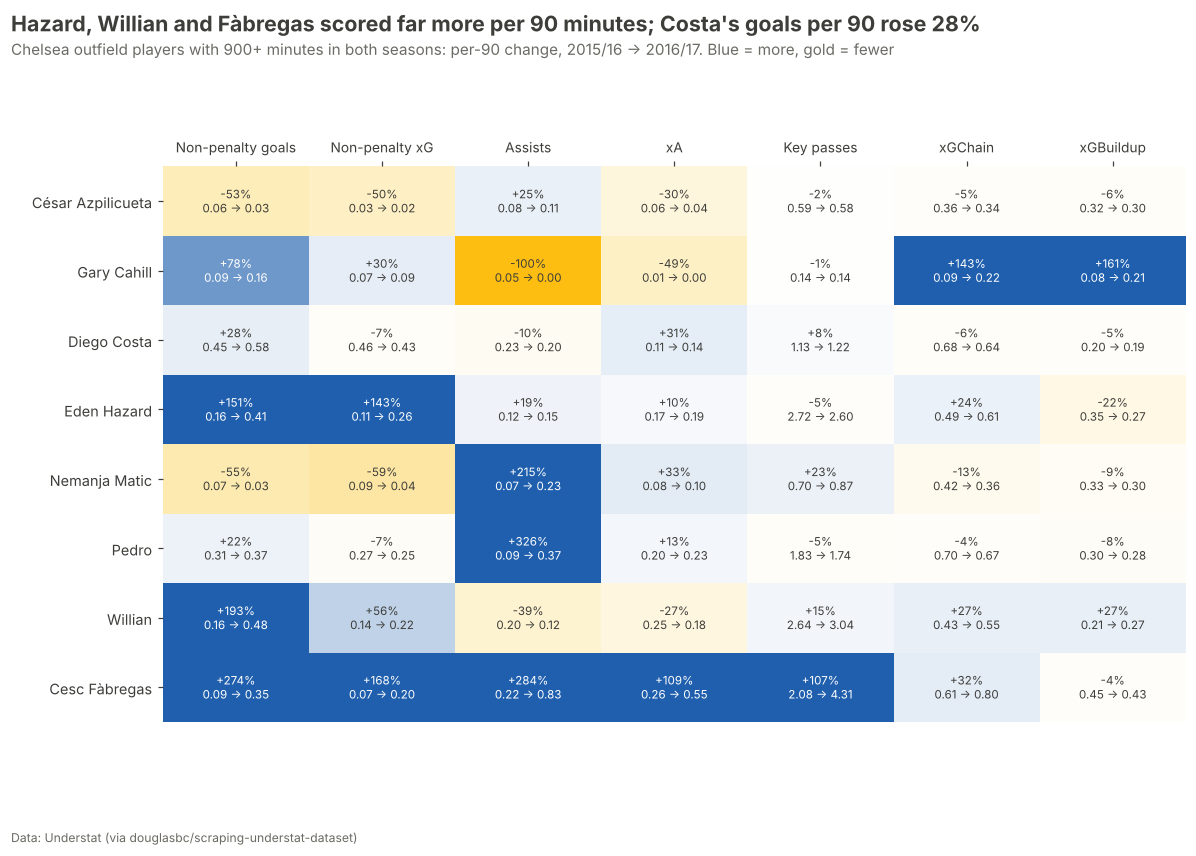

In [5]:
metrics = {"npg": "Non-penalty goals", "npxG": "Non-penalty xG", "assists": "Assists", "xA": "xA",
           "key_passes": "Key passes", "xGChain": "xGChain", "xGBuildup": "xGBuildup"}
def per90(df):
    d = df[df.team == CHE].set_index("player_name")
    out = d[list(metrics)].div(d.time, axis=0) * 90
    out["time"] = d.time
    return out
a, b = per90(P["2015/16"]), per90(P["2016/17"])
both = a.index.intersection(b.index)
both = [n for n in both if a.loc[n, "time"] >= 900 and b.loc[n, "time"] >= 900 and n != "Thibaut Courtois"]  # outfield only
chg = (b.loc[both, list(metrics)] - a.loc[both, list(metrics)])
pct = chg / a.loc[both, list(metrics)].replace(0, np.nan) * 100
order = b.loc[both].sort_values("time", ascending=False).index
fig, ax = plt.subplots(figsize=(12, 0.62 * len(order) + 1.6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("bg", [GOLD, "#FEF0C4", "#FFFFFF", "#D6E2F1", BLUE])
vals = pct.loc[order].clip(-100, 100).fillna(0)
ax.imshow(vals.values, cmap=cmap, vmin=-100, vmax=100, aspect="auto")
for i, n in enumerate(order):
    for j, m in enumerate(metrics):
        v0, v1, pc = a.loc[n, m], b.loc[n, m], pct.loc[n, m]
        txt = (f"{pc:+.0f}%" if np.isfinite(pc) else "new") + f"\n{v0:.2f} → {v1:.2f}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=7.6, color="white" if vals.loc[n, m] > 70 else DARK)
ax.set_xticks(range(len(metrics)), list(metrics.values()), fontsize=9)
ax.set_yticks(range(len(order)), order, fontsize=9.5)
ax.xaxis.tick_top(); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
titles(fig, "Hazard, Willian and Fàbregas scored far more per 90 minutes; Costa's goals per 90 rose 28%",
       "Chelsea outfield players with 900+ minutes in both seasons: per-90 change, 2015/16 → 2016/17. Blue = more, gold = fewer",
       SRC_U)
fig.savefig(FIGS / "11_returning_players_per90.png")
pct.loc[order].round(0)

## 4. The signings

Summer 2016 signings, from the [2016–17 Chelsea F.C. season](https://en.wikipedia.org/wiki/2016%E2%80%9317_Chelsea_F.C._season) transfers table:
Batshuayi £33.2m, Kanté £32m, Luiz £30m, Alonso £23m.

,time,share,fee,goals,xGChain,xGBuildup
player_name,,,,,,
N'Golo Kanté,3141,91.8,32.0,1,14.0,11.9
Michy Batshuayi,221,6.5,33.2,5,4.6,1.3
David Luiz,2959,86.5,30.0,1,7.6,6.9
Marcos Alonso,2696,78.8,23.0,6,13.1,8.2


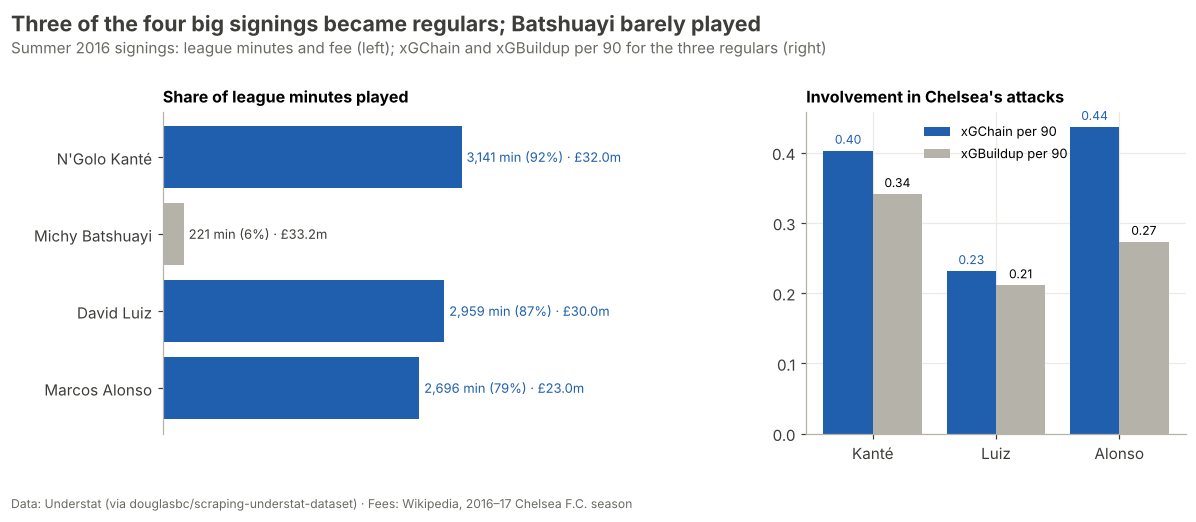

In [6]:
fees = {"N'Golo Kanté": 32.0, "Michy Batshuayi": 33.2, "David Luiz": 30.0, "Marcos Alonso": 23.0}
sig = p[p.player_name.isin(fees)].set_index("player_name").loc[list(fees)]
sig["fee"] = pd.Series(fees)
sig["share"] = sig.time / (38 * 90) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax = axes[0]
y = np.arange(len(sig))[::-1]
ax.barh(y, sig.share, color=[BLUE if s > 50 else GREY for s in sig.share])
for yi, (n, r) in zip(y, sig.iterrows()):
    ax.text(r.share + 1.5, yi, f"{r.time:,.0f} min ({r.share:.0f}%) · £{r.fee:.1f}m", va="center", fontsize=8.5,
            color=BLUE if r.share > 50 else DARK)
ax.set_yticks(y, sig.index); ax.set_xlim(0, 140); ax.set_xticks([]); ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.set_title("Share of league minutes played", fontsize=10.5)
ax = axes[1]
k = sig.loc[["N'Golo Kanté", "David Luiz", "Marcos Alonso"]]
x = np.arange(len(k))
ax.bar(x - 0.2, k.xGChain / k.time * 90, width=0.4, color=BLUE, label="xGChain per 90")
ax.bar(x + 0.2, k.xGBuildup / k.time * 90, width=0.4, color=GREY, label="xGBuildup per 90")
for xi, (n, r) in zip(x, k.iterrows()):
    ax.text(xi - 0.2, r.xGChain / r.time * 90 + 0.01, f"{r.xGChain / r.time * 90:.2f}", ha="center", fontsize=8, color=BLUE)
    ax.text(xi + 0.2, r.xGBuildup / r.time * 90 + 0.01, f"{r.xGBuildup / r.time * 90:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, [n.split()[-1] for n in k.index]); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Involvement in Chelsea's attacks", fontsize=10.5)
fig.subplots_adjust(wspace=0.45)
titles(fig, "Three of the four big signings became regulars; Batshuayi barely played",
       "Summer 2016 signings: league minutes and fee (left); xGChain and xGBuildup per 90 for the three regulars (right)",
       SRC_U + " · Fees: Wikipedia, 2016–17 Chelsea F.C. season")
fig.savefig(FIGS / "12_signings.png")
sig[["time", "share", "fee", "goals", "xGChain", "xGBuildup"]].round(1)

,Tackles,Interceptions,Passes,Pass completion %,Long-pass completion %
2015/16 Leicester,5.22,4.65,43.18,82.0,56.0
2016/17 Chelsea,3.64,2.35,60.84,89.0,78.0


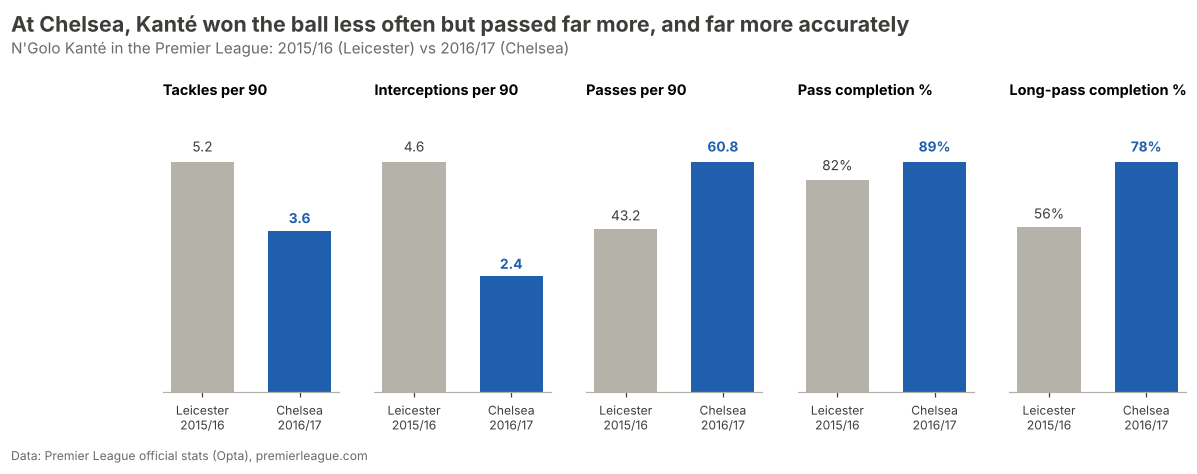

In [7]:
import re
def parse_raw(path):
    rows = {}
    for line in open(path, encoding="utf-8"):
        key, body = line.strip().split("#", 1)
        parts = body.split("|")
        rec = {}
        for i in range(len(parts) - 1):
            lab, val = parts[i], parts[i + 1]
            if not re.match(r"^[\d.,]+( \(\d+%\))?$", val) or re.match(r"^[\d.,]+( \(\d+%\))?$", lab):
                continue
            num = val.split(" ")[0]
            num = num.replace(".", "").replace(",", "") if re.match(r"^\d{1,3}([.,]\d{3})+$", num) else num.replace(",", ".")
            rec.setdefault(lab, float(num))
            m = re.search(r"\((\d+)%\)", val)
            if m:
                rec.setdefault(lab + " %", float(m.group(1)))
        rows[key] = rec
    return pd.DataFrame(rows).T
K = parse_raw(EXT / "pl_player_raw.txt").loc[["kante@2015", "kante@2016"]]
K90 = pd.DataFrame({
    "Tackles": K["Total Tackles"] / K["Minutes Played"] * 90,
    "Interceptions": K["Interceptions"] / K["Minutes Played"] * 90,
    "Passes": K["Passes (Completed %)"] / K["Minutes Played"] * 90,
    "Pass completion %": K["Passes (Completed %) %"],
    "Long-pass completion %": K["Long Passes (Completed %) %"],
}).rename(index={"kante@2015": "2015/16 Leicester", "kante@2016": "2016/17 Chelsea"})
fig, axes = plt.subplots(1, 5, figsize=(12, 3.4))
for ax, col in zip(axes, K90.columns):
    v = K90[col].values
    ax.bar([0, 1], v, color=[GREY, BLUE], width=0.65)
    for i, val in enumerate(v):
        ax.text(i, val * 1.03, f"{val:.1f}" if "%" not in col else f"{val:.0f}%", ha="center", va="bottom", fontsize=9,
                color=BLUE if i else DARK, fontweight="bold" if i else "normal")
    ax.set_title(col if "%" in col else f"{col} per 90", fontsize=9.5)
    ax.set_xticks([0, 1], ["Leicester\n2015/16", "Chelsea\n2016/17"], fontsize=8)
    ax.set_yticks([]); ax.set_ylim(0, v.max() * 1.25); ax.spines["left"].set_visible(False); ax.grid(False)
titles(fig, "At Chelsea, Kanté won the ball less often but passed far more, and far more accurately",
       "N'Golo Kanté in the Premier League: 2015/16 (Leicester) vs 2016/17 (Chelsea)", SRC_PL)
fig.savefig(FIGS / "13_kante_leicester_vs_chelsea.png")
K90.round(2)

## 5. The team's style (official Premier League stats)

The official club pages give season totals for passes, crosses, interceptions and more. One caveat: on these pages "Shots" is
always exactly twice "Shots on target" for every club, which can't be right, so shots come from Understat instead.

Goals Conceded                    33.0
Passes                         20125.0
Long Passes (Completed %) %       55.0
Crosses (Completed %)            485.0
Interceptions                    510.0
Blocks                            78.0
Clearances                       839.0
Dribbles (Completed %) %          66.0
Name: Chelsea, dtype: float64

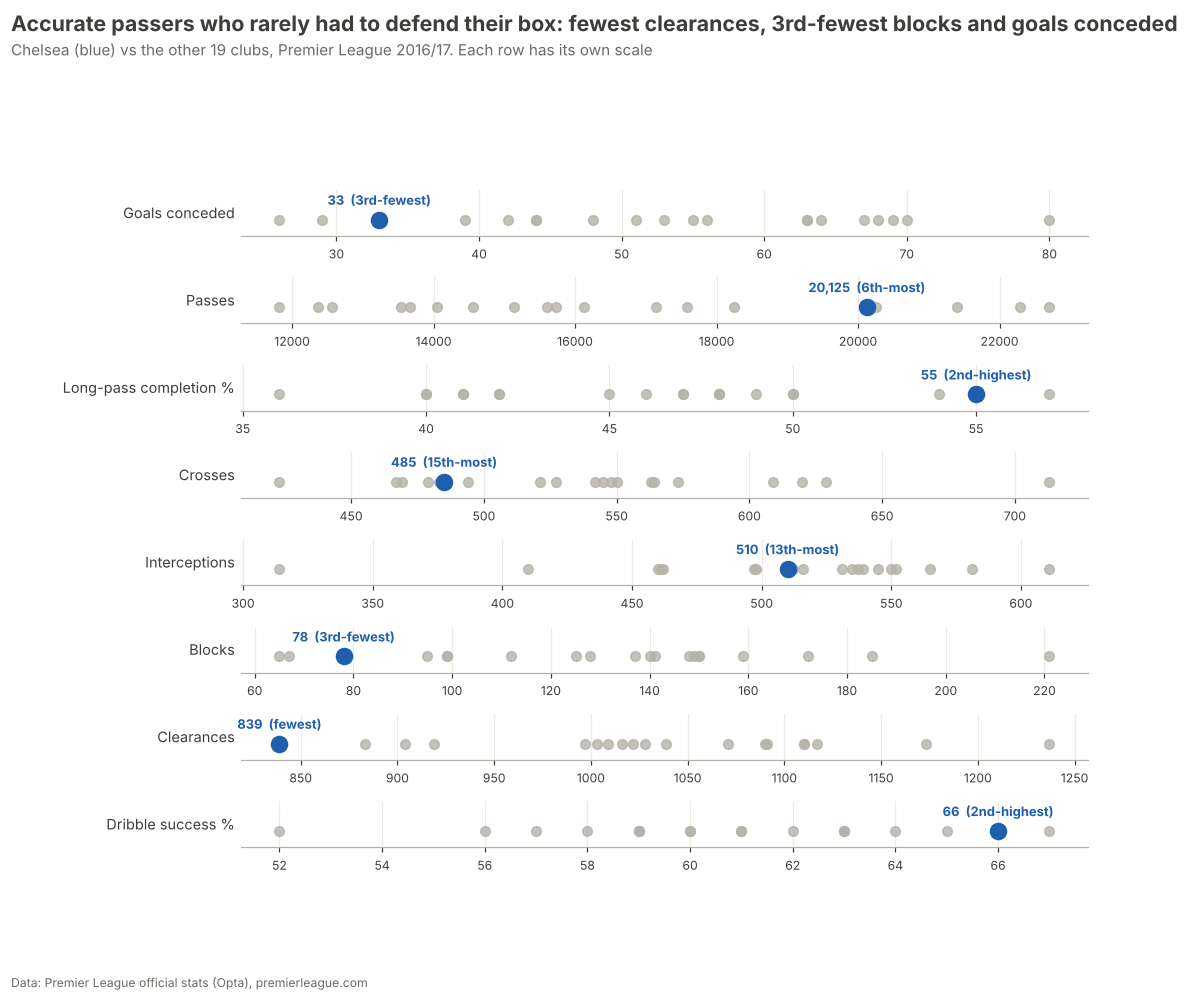

In [8]:
C = parse_raw(EXT / "pl_club_raw.txt")
C.index = C.index.str.replace("@", " ")
L = C[C.index.str.endswith("2016")].copy()
L.index = L.index.str.replace(" 2016", "").str.replace("-", " ").str.title()
L["Pass share %"] = L["Passes"] / L["Passes"].sum() * 2000 / 100   # passes as a share of a 20-team average (100 = average)
che_idx = "Chelsea"
show = {"Goals Conceded": ("Goals conceded", True), "Passes": ("Passes", False), "Long Passes (Completed %) %": ("Long-pass completion %", False),
        "Crosses (Completed %)": ("Crosses", False), "Interceptions": ("Interceptions", False), "Blocks": ("Blocks", True),
        "Clearances": ("Clearances", True), "Dribbles (Completed %) %": ("Dribble success %", False)}
fig, axes = plt.subplots(len(show), 1, figsize=(11, 0.82 * len(show) + 1.2))
for ax, (col, (lab, low_is_notable)) in zip(axes, show.items()):
    v = L[col].astype(float)
    rank = v.rank(ascending=low_is_notable, method="min").astype(int)
    ax.scatter(v.drop(che_idx), np.zeros(len(v) - 1), s=40, color=GREY, alpha=0.8)
    ax.scatter(v[che_idx], 0, s=110, color=BLUE, zorder=3)
    word = "fewest" if low_is_notable else "most" if "%" not in lab else "highest"
    rk = rank[che_idx]
    ordinal = "" if rk == 1 else f"{rk}{'nd' if rk == 2 else 'rd' if rk == 3 else 'th'}-"
    ax.text(v[che_idx], 0.55, f"{v[che_idx]:,.0f}  ({ordinal}{word})",
            ha="center", fontsize=8.5, color=BLUE, fontweight="bold")
    ax.set_yticks([]); ax.set_ylim(-0.6, 1.1)
    ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9.5)
    ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=8)
fig.subplots_adjust(hspace=0.9, left=0.2)
titles(fig, "Accurate passers who rarely had to defend their box: fewest clearances, 3rd-fewest blocks and goals conceded",
       "Chelsea (blue) vs the other 19 clubs, Premier League 2016/17. Each row has its own scale", SRC_PL)
fig.savefig(FIGS / "14_style_vs_league.png")
L.loc[che_idx, list(show)]

,2015/16,2016/17,pct
Blocks,136.0,78.0,-42.6
Goals conceded,53.0,33.0,-37.7
Offsides,90.0,64.0,-28.9
Dribbles attempted,822.0,762.0,-7.3
Duels won,2256.0,2145.0,-4.9
Interceptions,518.0,510.0,-1.5
Passes,19664.0,20125.0,2.3
Long passes,2312.0,2399.0,3.8
Crosses,466.0,485.0,4.1
Clearances,790.0,839.0,6.2


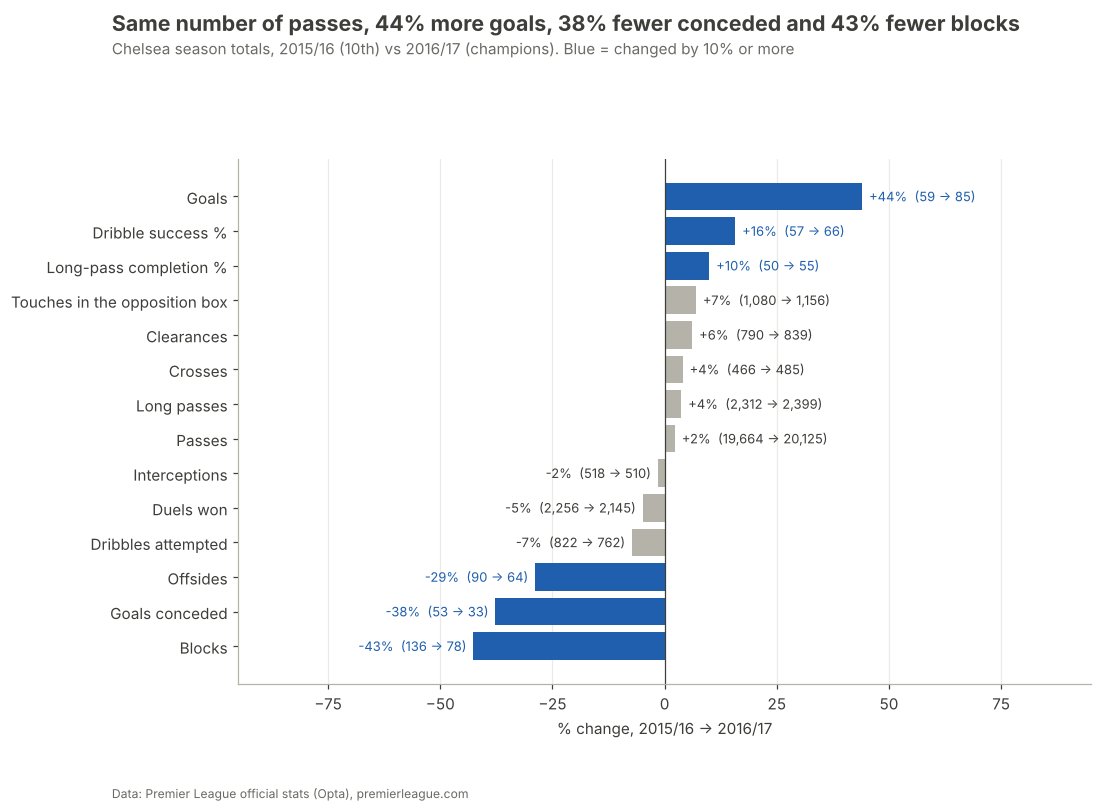

In [9]:
a, b = C.loc["chelsea 2015"], C.loc["chelsea 2016"]
rows = {"Goals": "Goals", "Goals Conceded": "Goals conceded", "Passes": "Passes", "Long Passes (Completed %)": "Long passes",
        "Long Passes (Completed %) %": "Long-pass completion %", "Crosses (Completed %)": "Crosses",
        "Touches in the Opposition Box": "Touches in the opposition box", "Dribbles (Completed %)": "Dribbles attempted",
        "Dribbles (Completed %) %": "Dribble success %", "Interceptions": "Interceptions", "Blocks": "Blocks",
        "Clearances": "Clearances", "Duels Won": "Duels won", "Offsides": "Offsides"}
ch = pd.DataFrame({"2015/16": a[list(rows)], "2016/17": b[list(rows)]}).astype(float)
ch["pct"] = (ch["2016/17"] / ch["2015/16"] - 1) * 100
ch = ch.rename(index=rows).sort_values("pct")
fig, ax = plt.subplots(figsize=(10, 6.2))
y = np.arange(len(ch))
cols = [BLUE if abs(v) >= 10 else GREY for v in ch.pct]
ax.barh(y, ch.pct, color=cols)
for yi, (n, r) in zip(y, ch.iterrows()):
    ax.text(r.pct + (1.5 if r.pct >= 0 else -1.5), yi, f"{r.pct:+.0f}%  ({r['2015/16']:,.0f} → {r['2016/17']:,.0f})",
            va="center", ha="left" if r.pct >= 0 else "right", fontsize=8.5, color=BLUE if abs(r.pct) >= 10 else DARK)
ax.set_yticks(y, ch.index); ax.axvline(0, color=DARK, lw=0.8)
ax.set_xlim(-95, 95); ax.set_xlabel("% change, 2015/16 → 2016/17"); ax.grid(axis="y", visible=False)
titles(fig, "Same number of passes, 44% more goals, 38% fewer conceded and 43% fewer blocks",
       "Chelsea season totals, 2015/16 (10th) vs 2016/17 (champions). Blue = changed by 10% or more", SRC_PL)
fig.savefig(FIGS / "15_chelsea_2015_16_vs_2016_17.png")
ch.round(1)

## 6. Conte's shapes: Juventus 3-5-2 and Chelsea 3-4-3

Positions as described by the tactical sources in the [article](../docs/ARTICLE.md) (SoccerTutor for Juventus, Spielverlagerung and
Wikipedia for Chelsea). This is a diagram of roles, not tracking data.

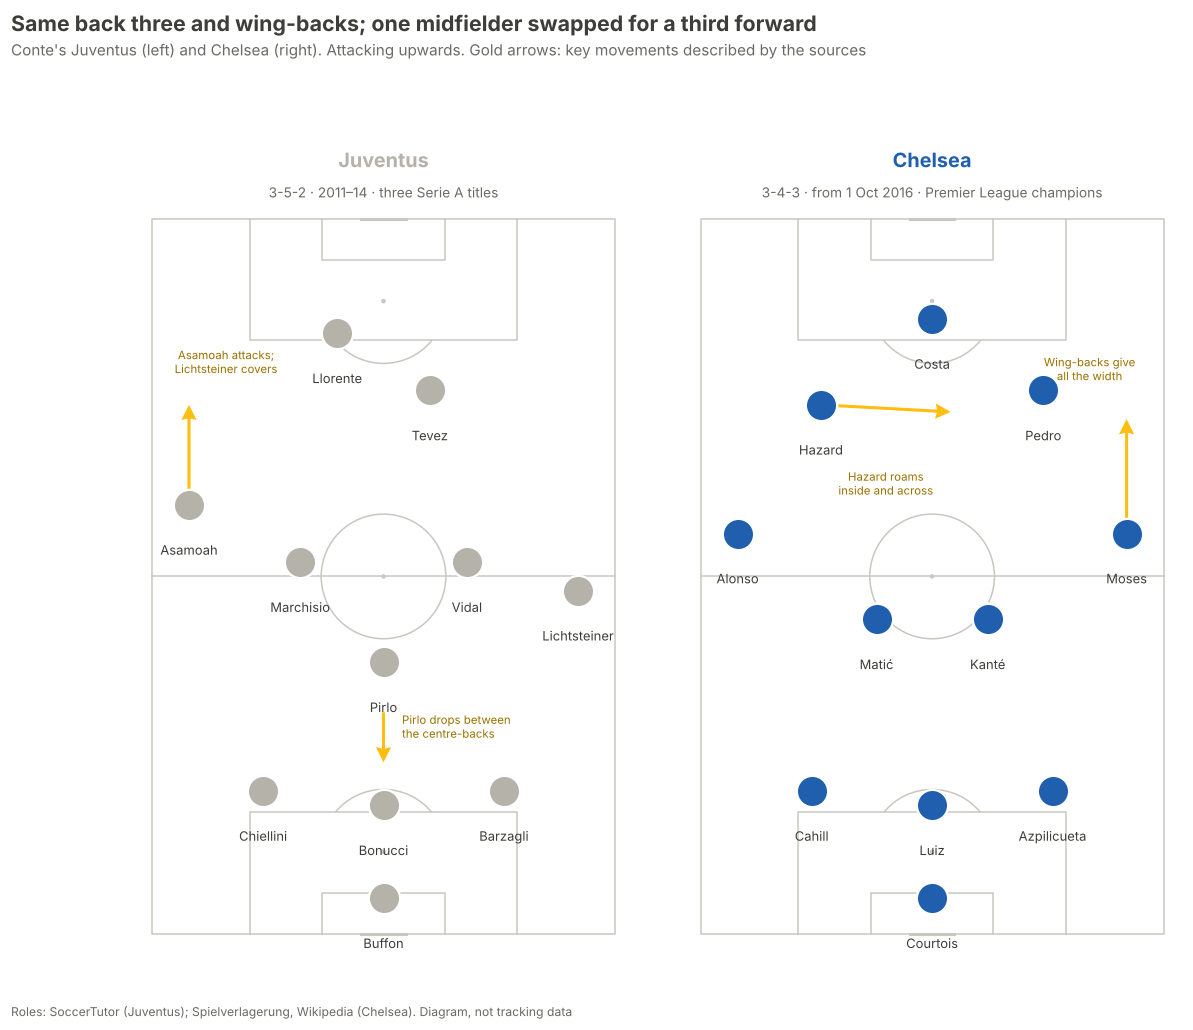

In [10]:
from mplsoccer import VerticalPitch
juve = {"Buffon": (50, 5), "Barzagli": (24, 20), "Bonucci": (50, 18), "Chiellini": (76, 20),
        "Lichtsteiner": (8, 48), "Vidal": (32, 52), "Pirlo": (50, 38), "Marchisio": (68, 52), "Asamoah": (92, 60),
        "Tevez": (40, 76), "Llorente": (60, 84)}
chel = {"Courtois": (50, 5), "Azpilicueta": (24, 20), "Luiz": (50, 18), "Cahill": (76, 20),
        "Moses": (8, 56), "Kanté": (38, 44), "Matić": (62, 44), "Alonso": (92, 56),
        "Pedro": (26, 76), "Costa": (50, 86), "Hazard": (74, 74)}
# (arrow start, arrow end, label, label position, label alignment). Pitch x runs 100 (left) to 0 (right) on screen.
moves = {"Juventus": [((50, 31), (50, 24), "Pirlo drops between\nthe centre-backs", (46, 29), "left"),
                      ((92, 60), (92, 74), "Asamoah attacks;\nLichtsteiner covers", (84, 80), "center")],
         "Chelsea": [((74, 74), (46, 73), "Hazard roams\ninside and across", (60, 63), "center"),
                     ((8, 56), (8, 72), "Wing-backs give\nall the width", (16, 79), "center")]}
pitch = VerticalPitch(pitch_type="opta", pitch_color="white", line_color="#C9C7BF", linewidth=1)
fig, axes = pitch.draw(nrows=1, ncols=2, figsize=(12, 8))
for ax, (name, team, sub) in zip(axes, [("Juventus", juve, "3-5-2 · 2011–14 · three Serie A titles"),
                                        ("Chelsea", chel, "3-4-3 · from 1 Oct 2016 · Premier League champions")]):
    col = GREY if name == "Juventus" else BLUE
    for (x0, y0), (x1, y1), lab, (lx, ly), ha in moves[name]:
        pitch.arrows(y0, x0, y1, x1, ax=ax, color=GOLD, width=2, headwidth=5, headlength=5, zorder=1)
        ax.text(lx, ly, lab, fontsize=7.5, color=GOLD_TEXT, ha=ha, va="center", zorder=4)
    for player, (x, y) in team.items():
        pitch.scatter(y, x, ax=ax, s=420, color=col, edgecolors="white", linewidth=1.5, zorder=3)
        ax.text(x, y - 5.2, player, ha="center", va="top", fontsize=8.5, color=DARK, zorder=4)
    ax.set_title(f"{name}\n", fontsize=13, fontweight="bold", color=col, loc="center")
    ax.text(50, 103, sub, ha="center", fontsize=9, color=MUTED)
titles(fig, "Same back three and wing-backs; one midfielder swapped for a third forward",
       "Conte's Juventus (left) and Chelsea (right). Attacking upwards. Gold arrows: key movements described by the sources",
       "Roles: SoccerTutor (Juventus); Spielverlagerung, Wikipedia (Chelsea). Diagram, not tracking data")
fig.savefig(FIGS / "16_formations_juventus_vs_chelsea.png")